In [1]:
from __future__ import annotations

import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import signal, linalg, stats
import matplotlib.pyplot as plt
import mne

mne.set_log_level("error")
warnings.filterwarnings("ignore", category=RuntimeWarning)

# ----------------------------------------------------------------------------------------------
# HEAD_MODEL = "fsaverage": full fsaverage anatomy and BEM (downloads ~200 MB once via
#                           mne.datasets.fetch_fsaverage). Use this for real results.
# HEAD_MODEL = "offline"  : no download. fsaverage5 cortex (bundled with nilearn), MNE's bundled
#                           fsaverage inner-skull surface, outer skull/scalp built by radial expansion.
# ----------------------------------------------------------------------------------------------
HEAD_MODEL = "fsaverage"
SUBJECTS_DIR = None                  # None → default MNE data folder (fetch_fsaverage)
OUT_DIR = Path("burst_sim_results")
QUICK_MODE = False                   # True: ~3 min smoke test (fewer seeds/SNRs, shorter recordings)
BURST_MODEL = "event"                # "event" (phenomenological bursts) or "jr" (Jansen–Rit column)
REAL_BACKGROUND_FILE = None          # optional: a resting EEG file (.bdf/.set/.fif) used as background

CFG = {
    "sfreq": 512.0,
    "duration": 120.0,                       # s per simulated recording
    "montage": "biosemi32",
    # ---- head models: data are GENERATED with "sim" and INVERTED with "inv" (avoids inverse crime)
    "sim_conductivity": (0.33, 0.0042, 0.33),  # brain, skull, scalp (S/m); skull ratio 1/80
    "inv_conductivity": (0.3, 0.006, 0.3),     # ratio 1/50, as commonly used in MNE pipelines
    "sim_electrode_jitter_mm": 5.0,            # real caps never sit exactly on the template positions
    "mindist_mm": 2.5,
    # ---- source configurations (fsaverage RAS ≈ MNI, mm)
    "regions": {
        "L_M1_hand": (-37.0, -21.0, 58.0),
        "L_PMd": (-25.0, -8.0, 62.0),
        "L_SMA": (-5.0, -5.0, 60.0),
        "R_M1_hand": (37.0, -21.0, 58.0),
        "R_PMd": (25.0, -8.0, 62.0),            # gives right M1 a neighbour to be confused with (symmetric design)
        "L_occipital": (-20.0, -92.0, 6.0),     # control region far from motor cortex
    },
    "deep_sources": {"L_thalamus": (-12.0, -18.0, 8.0)},   # e.g. add "L_STN": (-12, -14, -6)
    "deep_orientation": (0.0, 0.3, 1.0),        # unit-normalised; deep sources have no cortical normal
    "patch_radius_mm": 10.0,
    # ---- bursts: parameters per condition (rate = bursts/s during gaps; duration in s)
    "conditions": {
        "OFF": {"rate": 1.0, "dur_mean": 0.25, "dur_sd": 0.12, "amp": 1.3, "amp_cv": 0.3},
        "ON":  {"rate": 0.8, "dur_mean": 0.18, "dur_sd": 0.08, "amp": 1.0, "amp_cv": 0.3},
        "HC":  {"rate": 0.7, "dur_mean": 0.15, "dur_sd": 0.06, "amp": 1.0, "amp_cv": 0.3},
    },
    "burst_freq": (16.0, 24.0),
    "burst_sharpness": 0.3,                   # 0 = sinusoidal; >0 = sharper troughs (non-sinusoidal beta)
    # ---- background
    "n_background_sources": 300,
    "background_alpha_gain": 1.5,             # posterior alpha (sources with y < -50 mm)
    "background_beta_gain": 0.3,              # ongoing non-burst beta everywhere
    "sensor_noise": 0.05,                     # white sensor noise, fraction of background RMS
    # ---- detection
    "beta_band": (13.0, 30.0),
    "detect_percentile": 75.0,                # threshold on the ONE detection signal
    "min_cycles": 2.0,                        # minimum burst length in cycles at 20 Hz (= 100 ms)
    "merge_gap_s": 0.05,
    "detect_channel": "C3",
    "match_tolerance_s": 0.1,
    # ---- localization
    "evoked_band": (1.0, 45.0),
    "epoch_half_s": 0.3,
    "map_window_s": 0.025,                    # map = RMS over ±25 ms around the trough
    "lambda2": 1.0 / 9.0,
    "depth": 0.8,
    "depth_limit": 10.0,
    "lcmv_reg": 0.05,
    # ---- experiments
    "snr_db": (-10.0, -5.0, 0.0, 5.0),
    "n_seeds": 20,
    "n_noise_only": 20,
    "group_n": 15,                            # simulated patients for the OFF/ON experiment
    "group_location_jitter_mm": 6.0,
    "group_snr_db": -5.0,
    # ---- matched-head-model control: same BEM, conductivities and electrode positions for generation and
    #      inversion; isolates the resolution limit of 32-channel EEG from head-model mismatch
    "run_matched_control": True,
    "control_snr_db": (0.0, 5.0),
    "base_seed": 2026,
}
if QUICK_MODE:
    CFG.update(duration=60.0, snr_db=(-5.0, 5.0), n_seeds=3, n_noise_only=4, group_n=6, control_snr_db=(5.0,))

METHODS = ["pooled_any_dSPM", "dSPM", "sLORETA", "eLORETA", "LCMV", "dipole_scan", "dSPM_oracle"]
DETECTORS = ["pooled_any", "channel", "ged", "oracle"]
OUT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Anatomy and forward models

Both head models use the same cortex: fsaverage, mid-thickness positions (between white and pial
surfaces) with white-surface normals as fixed source orientations.
* **Generating space:** ico5 (10 242 vertices/hemisphere). Bursts and background live here.
* **Inverse space:** ico4 (2 562 vertices/hemisphere), a strict subset, so sources are never placed
  exactly on inverse grid points by construction of the patch.

The generating BEM uses a different skull conductivity and jittered electrode positions.

In [2]:
def _vertex_normals(rr, tris):
    fn = np.cross(rr[tris[:, 1]] - rr[tris[:, 0]], rr[tris[:, 2]] - rr[tris[:, 0]])
    nn = np.zeros_like(rr)
    for k in range(3):
        np.add.at(nn, tris[:, k], fn)
    norm = np.linalg.norm(nn, axis=1, keepdims=True)
    return nn / np.where(norm > 0, norm, 1.0)


def load_cortex(head_model, subjects_dir):
    """Mid-thickness positions (m), normals and hemisphere labels of fsaverage ico5 vertices."""
    rr, nn, hemi = [], [], []
    if head_model == "fsaverage":
        for h, lab in (("lh", 0), ("rh", 1)):
            wr, wt = mne.read_surface(os.path.join(subjects_dir, "fsaverage", "surf", f"{h}.white"))
            pr, _ = mne.read_surface(os.path.join(subjects_dir, "fsaverage", "surf", f"{h}.pial"))
            n = _vertex_normals(wr, wt)[:10242]          # fsaverage is icosahedral: first 10242 = ico5
            rr.append((wr[:10242] + pr[:10242]) / 2.0); nn.append(n); hemi.append(np.full(10242, lab))
    else:
        from nilearn import datasets
        fs = datasets.load_fsaverage("fsaverage5")
        for h, lab in (("left", 0), ("right", 1)):
            w, p = fs["white_matter"].parts[h], fs["pial"].parts[h]
            rr.append((w.coordinates + p.coordinates) / 2.0)
            nn.append(_vertex_normals(w.coordinates, w.faces)); hemi.append(np.full(len(w.coordinates), lab))
    rr = np.concatenate(rr) / 1000.0
    nn = np.concatenate(nn)
    hemi = np.concatenate(hemi)
    ico4 = np.concatenate([np.arange(2562), 10242 + np.arange(2562)])
    return {"rr": rr, "nn": nn, "hemi": hemi, "ico4": ico4}


def offline_subjects_dir(root: Path) -> Path:
    """Fake FreeSurfer folder with fsaverage BEM surfaces built from MNE's bundled inner skull."""
    sd = root / "offline_subjects"
    bem_dir = sd / "fsaverage" / "bem"
    if (bem_dir / "outer_skin.surf").exists():
        return sd
    bem_dir.mkdir(parents=True, exist_ok=True)
    inner = mne.read_bem_surfaces(os.path.join(os.path.dirname(mne.__file__), "data", "fsaverage",
                                               "fsaverage-inner_skull-bem.fif"))[0]
    rr, tris = inner["rr"] * 1000.0, inner["tris"]           # MRI coords, mm
    c = rr.mean(0)
    for name, d in (("inner_skull", 0.0), ("outer_skull", 7.0), ("outer_skin", 14.0)):
        v = rr - c
        out = c + v * (1.0 + d / np.linalg.norm(v, axis=1, keepdims=True))   # radial expansion by d mm
        mne.write_surface(str(bem_dir / f"{name}.surf"), out, tris, overwrite=True)
    return sd


def eeg_info(cfg, jitter_mm=0.0, seed=0):
    names = mne.channels.make_standard_montage(cfg["montage"]).ch_names
    info = mne.create_info(names, cfg["sfreq"], "eeg")
    info.set_montage(cfg["montage"])
    if jitter_mm > 0:
        rng = np.random.default_rng(seed)
        with info._unlock():
            for ch in info["chs"]:
                ch["loc"][:3] += rng.normal(0, jitter_mm / 1000.0 / np.sqrt(3), 3)
    return info


def bem_solution(subjects_dir, conductivity, cache: Path):
    if cache.exists():
        return mne.read_bem_solution(cache)
    model = mne.make_bem_model("fsaverage", ico=4, conductivity=conductivity, subjects_dir=subjects_dir)
    sol = mne.make_bem_solution(model)
    mne.write_bem_solution(cache, sol, overwrite=True)
    return sol


def fixed_gain(info, trans, rr, nn, bem, mindist_mm):
    """Fixed-orientation gain matrix (n_ch × n_src) for discrete sources; returns kept indices."""
    src = mne.setup_volume_source_space(pos=dict(rr=rr, nn=nn), bem=bem, mindist=0.0, exclude=0.0)
    fwd = mne.make_forward_solution(info, trans, src, bem, eeg=True, meg=False, mindist=mindist_mm)
    fwd = mne.convert_forward_solution(fwd, surf_ori=True, force_fixed=True)
    kept = src[0]["vertno"]
    kept = kept[np.isin(kept, fwd["src"][0]["vertno"])]
    G = fwd["sol"]["data"]
    return G, kept


def free_gain(info, trans, pos, bem):
    src = mne.setup_volume_source_space(pos=dict(rr=np.atleast_2d(pos), nn=np.tile([0, 0, 1.0], (len(np.atleast_2d(pos)), 1))),
                                        bem=bem, mindist=0.0, exclude=0.0)
    fwd = mne.make_forward_solution(info, trans, src, bem, eeg=True, meg=False, mindist=0.0)
    return fwd["sol"]["data"]                    # n_ch × 3 (x, y, z in head coordinates)


def build_anatomy(cfg, head_model=HEAD_MODEL, subjects_dir=SUBJECTS_DIR, out_dir=OUT_DIR, verbose=True,
                  matched=False, reuse_inverse=None):
    """Cortex, generating and inverse gain matrices, regions, deep-source gains.

    matched=True generates data with the INVERSE head model (same conductivities, no electrode jitter);
    only the source space differs (ico5 generation vs ico4 inversion). reuse_inverse: an anatomy dict
    whose inverse gain matrix is reused, to avoid recomputing it."""
    t0 = time.time()
    if head_model == "fsaverage":
        fs_dir = mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir, verbose=False)
        subjects_dir = str(Path(fs_dir).parent)
    else:
        subjects_dir = str(offline_subjects_dir(out_dir))
    trans = os.path.join(os.path.dirname(mne.__file__), "data", "fsaverage", "fsaverage-trans.fif")
    cortex = load_cortex(head_model, subjects_dir)
    tag = head_model
    bem_inv = bem_solution(subjects_dir, cfg["inv_conductivity"], out_dir / f"bem_inv_{tag}-sol.fif")
    bem_sim = bem_inv if matched else bem_solution(subjects_dir, cfg["sim_conductivity"],
                                                   out_dir / f"bem_sim_{tag}-sol.fif")
    info_inv = eeg_info(cfg)
    info_sim = info_inv if matched else eeg_info(cfg, cfg["sim_electrode_jitter_mm"], cfg["base_seed"])

    G_sim, kept_sim = fixed_gain(info_sim, trans, cortex["rr"], cortex["nn"], bem_sim, cfg["mindist_mm"])
    ok_s = np.linalg.norm(G_sim, axis=0) > 1e-3 * np.median(np.linalg.norm(G_sim, axis=0))
    G_sim, kept_sim = G_sim[:, ok_s], kept_sim[ok_s]      # drop degenerate (medial-wall) columns
    if reuse_inverse is not None:
        G_inv, kept_inv = reuse_inverse["G_inv"], reuse_inverse["kept_inv"]
    else:
        inv_idx = cortex["ico4"]
        G_inv, kept_inv_local = fixed_gain(info_inv, trans, cortex["rr"][inv_idx], cortex["nn"][inv_idx],
                                           bem_inv, cfg["mindist_mm"])
        kept_inv = inv_idx[kept_inv_local]
        ok_i = np.linalg.norm(G_inv, axis=0) > 1e-3 * np.median(np.linalg.norm(G_inv, axis=0))
        G_inv, kept_inv = G_inv[:, ok_i], kept_inv[ok_i]

    pos_sim_mm = cortex["rr"][kept_sim] * 1000.0
    pos_inv_mm = cortex["rr"][kept_inv] * 1000.0
    anat = {"cortex": cortex, "G_sim": G_sim, "G_inv": G_inv, "kept_sim": kept_sim, "kept_inv": kept_inv,
            "pos_sim": pos_sim_mm, "pos_inv": pos_inv_mm, "hemi_sim": cortex["hemi"][kept_sim],
            "hemi_inv": cortex["hemi"][kept_inv], "ch_names": info_inv.ch_names, "info": info_inv,
            "regions": {}, "deep": {}, "matched": matched}

    # cortical patches: sim-space vertices within radius of the seed (same hemisphere)
    for name, seed in cfg["regions"].items():
        seed = np.asarray(seed)
        h = 0 if seed[0] < 0 else 1
        cand = np.where(anat["hemi_sim"] == h)[0]
        centre = cand[np.argmin(np.linalg.norm(pos_sim_mm[cand] - seed, axis=1))]
        patch = cand[np.linalg.norm(pos_sim_mm[cand] - pos_sim_mm[centre], axis=1) <= cfg["patch_radius_mm"]]
        g = G_sim[:, patch].mean(axis=1)
        anat["regions"][name] = {"kind": "cortical", "seed": seed, "patch_sim": patch,
                                 "centroid": pos_sim_mm[patch].mean(0), "gain": g, "hemi": h}
    # deep sources: free-orientation gain projected on a fixed orientation
    ori = np.asarray(cfg["deep_orientation"], float); ori /= np.linalg.norm(ori)
    for name, p in cfg["deep_sources"].items():
        Gf = free_gain(info_sim, trans, np.asarray(p) / 1000.0, bem_sim)
        anat["regions"][name] = {"kind": "deep", "seed": np.asarray(p, float), "patch_sim": np.array([], int),
                                 "centroid": np.asarray(p, float), "gain": Gf @ ori,
                                 "hemi": 0 if p[0] < 0 else 1}
    if verbose:
        print(f"anatomy ({head_model}{', MATCHED control' if matched else ''}): generating sources {G_sim.shape[1]}, inverse sources {G_inv.shape[1]}, "
              f"{time.time() - t0:.0f} s")
        for name, r in anat["regions"].items():
            print(f"   {name:12s} {r['kind']:9s} centroid {np.round(r['centroid'], 1)} "
                  f"patch vertices {len(r['patch_sim'])}")
        cort = {k: v["centroid"] for k, v in anat["regions"].items() if v["kind"] == "cortical"}
        for a, b in (("L_M1_hand", "L_PMd"), ("R_M1_hand", "R_PMd"), ("L_PMd", "L_SMA")):
            if a in cort and b in cort:
                print(f"   centroid distance {a}–{b}: {np.linalg.norm(cort[a] - cort[b]):.1f} mm")
    return anat

## 2. Burst generator

**`event` model.** Bursts arrive as a renewal process (gap ~ exponential with mean 1/rate). Each burst
has a log-normal duration, a frequency drawn from `burst_freq`, a log-normal amplitude, and a Hann
envelope. The waveform `−(cos θ + s·cos 2θ)/(1+s)` gives sharp troughs and broad peaks for `s > 0`, as in
non-sinusoidal motor beta. Ground truth for each burst: onset, offset and the time of its deepest trough.

**`jr` model.** A Jansen–Rit column at beta speed (k = 2) driven by a slowly fluctuating input that
crosses its Hopf point, so bursts emerge from the dynamics. Ground truth is extracted from the source
signal itself with the same rules used for detection (single signal, percentile threshold, ≥ 2 cycles).

In [3]:
def burst_events(rng, n, sfreq, cond, cfg):
    """Phenomenological beta bursts. Returns the source time course and a list of event dicts."""
    s = np.zeros(n)
    events = []
    t = int(rng.exponential(1.0 / cond["rate"]) * sfreq)
    sig = np.sqrt(np.log(1 + (cond["dur_sd"] / cond["dur_mean"]) ** 2))
    mu = np.log(cond["dur_mean"]) - sig ** 2 / 2
    while True:
        d = float(np.clip(rng.lognormal(mu, sig), 0.06, 1.0))
        L = int(d * sfreq)
        if t + L >= n - 1:
            break
        f = rng.uniform(*cfg["burst_freq"])
        a = cond["amp"] * rng.lognormal(-cond["amp_cv"] ** 2 / 2, cond["amp_cv"])
        th = 2 * np.pi * f * np.arange(L) / sfreq + rng.uniform(0, 2 * np.pi)
        sh = cfg["burst_sharpness"]
        seg = a * np.hanning(L) * (-(np.cos(th) + sh * np.cos(2 * th)) / (1 + sh))
        s[t:t + L] += seg
        events.append({"onset": t, "offset": t + L, "trough": t + int(np.argmin(seg)), "freq": f, "amp": a,
                       "dur": d})
        t += L + int(rng.exponential(1.0 / cond["rate"]) * sfreq)
    return s, events


def jr_bursts(rng, n, sfreq, cond, cfg, dt=2.5e-4):
    """Noise-driven Jansen–Rit column at beta speed with an input that drifts across its Hopf point."""
    k = 2.0
    A, B, a, b = 3.25 * k, 22.0 * k, 100.0 * k, 50.0 * k
    C = 135.0
    C1, C2, C3, C4 = C, 0.8 * C, 0.25 * C, 0.25 * C
    e0, v0, r = 2.5, 6.0, 0.56
    S = lambda v: 2 * e0 / (1 + np.exp(r * (v0 - v)))
    steps_per_sample = int(round(1.0 / (sfreq * dt)))
    n_steps = n * steps_per_sample
    # slow input: OU process around a sub-threshold mean; crossings of ~345 produce bursts
    tau, mu0 = 0.4, 330.0 + 20.0 * (cond["amp"] - 1.0)
    sd = 18.0 * (cond["dur_mean"] / 0.2)
    ou = np.empty(n)
    x = 0.0
    for i in range(n):
        x += (-x / tau) / sfreq + np.sqrt(2 / tau / sfreq) * rng.standard_normal()
        ou[i] = x
    p_slow = mu0 + sd * ou
    y = np.zeros(6)
    out = np.empty(n)
    xi = rng.standard_normal(n_steps)
    for i in range(n):
        p = p_slow[i]
        for j in range(steps_per_sample):
            y0, y1, y2, y3, y4, y5 = y
            d3 = A * a * S(y1 - y2) - 2 * a * y3 - a * a * y0
            d4 = A * a * (p + C2 * S(C1 * y0)) - 2 * a * y4 - a * a * y1
            d5 = B * b * C4 * S(C3 * y0) - 2 * b * y5 - b * b * y2
            y = y + dt * np.array([y3, y4, y5, d3, d4, d5])
            y[4] += A * a * 2.0 * np.sqrt(dt) * xi[i * steps_per_sample + j]
        out[i] = y[1] - y[2]
    out = out - out.mean()
    s = signal.sosfiltfilt(signal.butter(4, cfg["beta_band"], "band", fs=sfreq, output="sos"), out)
    events = detect_from_signal(s, sfreq, cfg)
    return s / np.std(s) * cond["amp"], events


def make_source(rng, n, sfreq, cond, cfg, model=BURST_MODEL):
    return burst_events(rng, n, sfreq, cond, cfg) if model == "event" else jr_bursts(rng, n, sfreq, cond, cfg)

## 3. Background and scalp synthesis

Background = `n_background_sources` random cortical dipoles carrying 1/f noise, plus posterior alpha
and weak ongoing (non-burst) beta, projected through the generating forward model; or a real resting
EEG file (`REAL_BACKGROUND_FILE`, which itself contains real bursts, so its ground truth is impure).

**SNR** = RMS of the burst signal during bursts ÷ RMS of the background in the beta band, both at the
channel where the burst projects most strongly (in dB). Scalp data are then average-referenced.

In [4]:
def pink_noise(rng, k, n, exponent=1.0):
    spec = np.fft.rfft(rng.standard_normal((k, n)), axis=1)
    f = np.arange(spec.shape[1], dtype=float); f[0] = 1.0
    x = np.fft.irfft(spec / f ** (exponent / 2), n, axis=1)
    return x / x.std(axis=1, keepdims=True)


def bandpass(x, band, sfreq, order=4):
    sos = signal.butter(order, band, btype="band", fs=sfreq, output="sos")
    return signal.sosfiltfilt(sos, x, axis=-1)


def make_background(rng, n, anat, cfg, exclude=()):
    sfreq = cfg["sfreq"]
    if REAL_BACKGROUND_FILE:
        raw = mne.io.read_raw(REAL_BACKGROUND_FILE, preload=True)
        raw.pick([c for c in anat["ch_names"] if c in raw.ch_names]).resample(sfreq).filter(1.0, 100.0)
        if len(raw.ch_names) < len(anat["ch_names"]):
            raise ValueError("REAL_BACKGROUND_FILE lacks some montage channels")
        X = raw.reorder_channels(anat["ch_names"]).get_data()
        if X.shape[1] < n:
            raise ValueError("REAL_BACKGROUND_FILE is shorter than CFG['duration']")
        X = X[:, :n]
        return X / X.std()
    m = anat["G_sim"].shape[1]
    pool = np.setdiff1d(np.arange(m), np.asarray(exclude, int))
    idx = rng.choice(pool, cfg["n_background_sources"], replace=False)
    S = pink_noise(rng, len(idx), n)
    post = anat["pos_sim"][idx, 1] < -50.0
    if post.any():
        S[post] += cfg["background_alpha_gain"] * bandpass(rng.standard_normal((post.sum(), n)), (8.5, 11.5), sfreq) * 6
    S += cfg["background_beta_gain"] * bandpass(rng.standard_normal((len(idx), n)), cfg["beta_band"], sfreq) * 3
    X = anat["G_sim"][:, idx] @ S
    X = X - X.mean(axis=0, keepdims=True)
    return X / X.std()


def synthesize(rng, anat, region, cond_name, snr_db, cfg, n=None, gain_override=None, with_bursts=True):
    """Average-referenced scalp data (n_ch × n), the burst source course and ground-truth events."""
    sfreq = cfg["sfreq"]
    n = n or int(cfg["duration"] * sfreq)
    reg = anat["regions"][region]
    X_bg = make_background(rng, n, anat, cfg, exclude=reg["patch_sim"])
    g = reg["gain"] if gain_override is None else gain_override
    g = g - g.mean()
    if with_bursts:
        s, events = make_source(rng, n, sfreq, cfg["conditions"][cond_name], cfg)
    else:
        s, events = np.zeros(n), []
    best = int(np.argmax(np.abs(g)))
    bg_beta_rms = np.std(bandpass(X_bg[best], cfg["beta_band"], sfreq))
    in_burst = np.abs(s) > 0
    if with_bursts and in_burst.any():
        burst_rms = np.sqrt(np.mean((g[best] * s[in_burst]) ** 2))
        scale = 10 ** (snr_db / 20) * bg_beta_rms / burst_rms
    else:
        scale = 0.0
    X = X_bg + scale * np.outer(g, s)
    X += cfg["sensor_noise"] * rng.standard_normal(X.shape)
    X -= X.mean(axis=0, keepdims=True)                        # average reference
    return X, s * scale, events

## 4. Burst detection

All detectors share one rule set: band-pass 13–30 Hz, Hilbert envelope, threshold at the
`detect_percentile` **of that one signal**, keep runs ≥ `min_cycles` cycles, merge gaps < 50 ms, and
place one event at the deepest beta trough of each burst.

| Detector | Detection signal |
|---|---|
| `pooled_any` | one percentile pooled over all channels; a sample counts if **any** channel exceeds it; every such sample is a trigger (shown for comparison) |
| `channel` | one chosen channel (`detect_channel`, default C3) |
| `ged` | the leading generalized-eigenvector component of beta-band vs broadband covariance |
| `oracle` | the true burst troughs (upper bound) |

**Threshold scope.** A percentile threshold set separately for each recording always marks about
(100 − percentile)% of that recording as "burst", so it normalises away genuine differences in burst
rate between conditions. For OFF/ON comparisons, `shared_ged()` fits one GED filter and one threshold to
the pooled OFF+ON data of each subject, and both conditions are detected with them (section 7).

In [5]:
def _runs(mask):
    d = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    return list(zip(np.where(d == 1)[0], np.where(d == -1)[0]))


def detect_from_signal(beta_sig, sfreq, cfg, thr=None):
    """Bursts on one beta-filtered signal → list of {onset, offset, trough}. thr=None: percentile of this signal."""
    env = np.abs(signal.hilbert(beta_sig))
    if thr is None:
        thr = np.percentile(env, cfg["detect_percentile"])
    runs = _runs(env > thr)
    merged = []
    for a, b in runs:
        if merged and a - merged[-1][1] < cfg["merge_gap_s"] * sfreq:
            merged[-1] = (merged[-1][0], b)
        else:
            merged.append((a, b))
    min_len = cfg["min_cycles"] / 20.0 * sfreq
    out = []
    for a, b in merged:
        if b - a >= min_len:
            out.append({"onset": a, "offset": b, "trough": a + int(np.argmin(beta_sig[a:b]))})
    return out


def ged_filter(X, sfreq, cfg):
    """Spatial filter maximising beta-band power relative to broadband power (avg-ref safe)."""
    U = null_ref_basis(X.shape[0])
    Xr = U.T @ X
    Xb = bandpass(Xr, cfg["beta_band"], sfreq)
    Cb, Ca = np.cov(Xb), np.cov(Xr)
    Ca += 1e-6 * np.trace(Ca) / len(Ca) * np.eye(len(Ca))
    evals, evecs = linalg.eigh(Cb, Ca)
    w = evecs[:, -1]
    return U @ w


def shared_ged(Xs, sfreq, cfg):
    """One GED filter and one envelope threshold fitted to several recordings of the same subject."""
    w = ged_filter(np.concatenate(Xs, axis=1), sfreq, cfg)
    env = np.concatenate([np.abs(signal.hilbert(bandpass(w @ X, cfg["beta_band"], sfreq))) for X in Xs])
    return w, float(np.percentile(env, cfg["detect_percentile"]))


def detect(X, sfreq, cfg, method, true_events=None, ch_names=None, ged_override=None):
    """Returns (events, extra) for one detector. ged_override = (filter, threshold) from shared_ged()."""
    if method == "oracle":
        return [dict(e) for e in true_events], {}
    if method == "pooled_any":
        env = np.abs(signal.hilbert(bandpass(X, cfg["beta_band"], sfreq), axis=1))
        trig = np.where((env > np.percentile(env, 75)).any(axis=0))[0]
        return [{"onset": t, "offset": t + 1, "trough": t} for t in trig], {"fraction_flagged": len(trig) / X.shape[1]}
    if method == "channel":
        sig = bandpass(X[ch_names.index(cfg["detect_channel"])], cfg["beta_band"], sfreq)
        return detect_from_signal(sig, sfreq, cfg), {}
    if method == "ged":
        w, thr = ged_override if ged_override is not None else (ged_filter(X, sfreq, cfg), None)
        sig = bandpass(w @ X, cfg["beta_band"], sfreq)
        return detect_from_signal(sig, sfreq, cfg, thr), {"filter": w}
    raise ValueError(method)


def detection_scores(true_events, det_events, sfreq, tol_s):
    """Precision / recall / F1 by matching trough times within ±tol (greedy, one-to-one)."""
    if len(det_events) > 5 * max(len(true_events), 1):          # trigger-per-sample methods
        return {"precision": len(true_events) / len(det_events), "recall": 1.0 if true_events else np.nan,
                "f1": 2 * len(true_events) / (len(det_events) + len(true_events)) if det_events else 0.0,
                "n_detected": len(det_events)}
    t_true = np.array([e["trough"] for e in true_events])
    t_det = np.array([e["trough"] for e in det_events])
    tol = tol_s * sfreq
    used = np.zeros(len(t_true), bool)
    hits = 0
    for t in t_det:
        if len(t_true) == 0:
            break
        d = np.abs(t_true - t).astype(float)
        d[used] = np.inf
        j = int(np.argmin(d))
        if d[j] <= tol:
            used[j] = True
            hits += 1
    p = hits / len(t_det) if len(t_det) else np.nan
    r = hits / len(t_true) if len(t_true) else np.nan
    f1 = 2 * p * r / (p + r) if p and r and (p + r) > 0 else 0.0
    return {"precision": p, "recall": r, "f1": f1, "n_detected": len(t_det)}

## 5. Source localization

All inverses are implemented directly on the fixed-orientation gain matrix, in the (n−1)-dimensional
space orthogonal to the average reference, after whitening with the noise covariance.

* **MNE kernel:** `K = R G̃ᵀ (G̃ R G̃ᵀ + λ² I)⁻¹`, depth prior `R_j ∝ ‖g̃_j‖^(−2·depth)` (max/min ratio
  capped at `depth_limit`), `R` scaled so `tr(G̃ R G̃ᵀ) = rank`.
* **dSPM:** rows of `K` divided by `√(K Kᵀ)_jj` (whitened noise = I); evoked whitened with `C/nave`.
* **sLORETA:** rows divided by `√(K (G̃ R G̃ᵀ + λ²I) Kᵀ)_jj`.
* **eLORETA:** iterative weights `w_j = √(g̃_jᵀ M g̃_j)`, `M = (G̃ W⁻¹ G̃ᵀ + α I)⁻¹`.
* **LCMV:** beta-band burst covariance vs burst-free covariance, unit-gain filters from their
  (regularised) average; map = power ratio burst / burst-free.
* **Dipole scan:** goodness of fit of every single fixed dipole to the whitened trough topography.

Evoked-based maps take the RMS over ±25 ms around the trough.

In [6]:
def null_ref_basis(n):
    """Orthonormal basis (n × n−1) of the space orthogonal to the all-ones (average-reference) vector."""
    q, _ = np.linalg.qr(np.column_stack([np.ones(n), np.eye(n)[:, :n - 1]]))
    return q[:, 1:]


def whitener(C):
    lam, V = linalg.eigh(C)
    lam = np.maximum(lam, lam.max() * 1e-10)
    return (V / np.sqrt(lam)).T


def mne_kernels(Gw, cfg):
    norms2 = np.sum(Gw ** 2, axis=0)
    R = norms2 ** (-cfg["depth"])
    R = np.minimum(R, R.min() * cfg["depth_limit"])
    r = Gw.shape[0]
    R *= r / np.sum(norms2 * R)
    A = (Gw * R) @ Gw.T + cfg["lambda2"] * np.eye(r)
    Ainv = linalg.inv(A)
    K = (R[:, None] * Gw.T) @ Ainv
    dspm = np.sqrt(np.sum(K ** 2, axis=1))
    slor = np.sqrt(np.sum(K * (K @ A), axis=1))
    return K, dspm, slor


def eloreta_kernel(Gw, cfg, n_iter=50, tol=1e-6):
    r, m = Gw.shape
    w = np.ones(m)
    for _ in range(n_iter):
        GWG = (Gw / w) @ Gw.T
        alpha = cfg["lambda2"] * np.trace(GWG) / r
        M = linalg.inv(GWG + alpha * np.eye(r))
        w_new = np.sqrt(np.sum(Gw * (M @ Gw), axis=0))
        if np.max(np.abs(w_new - w) / w) < tol:
            w = w_new
            break
        w = w_new
    GWG = (Gw / w) @ Gw.T
    M = linalg.inv(GWG + cfg["lambda2"] * np.trace(GWG) / r * np.eye(r))
    return (Gw / w).T @ M


def epochs_around(X, triggers, half):
    triggers = np.asarray([t for t in triggers if half <= t < X.shape[1] - half], int)
    if len(triggers) == 0:
        return np.zeros((0, X.shape[0], 2 * half + 1)), triggers
    idx = triggers[:, None] + np.arange(-half, half + 1)[None, :]
    return X[:, idx].transpose(1, 0, 2), triggers


def burst_free_mask(n, events, pad):
    m = np.ones(n, bool)
    for e in events:
        m[max(0, e["onset"] - pad):min(n, e["offset"] + pad)] = False
    return m


def localize(X, events, anat, cfg, methods, sfreq):
    """Maps (one value per inverse source) for each requested method, from one set of events."""
    n_ch, n = X.shape
    U = null_ref_basis(n_ch)
    Gr = U.T @ anat["G_inv"]
    Xe = bandpass(X, cfg["evoked_band"], sfreq)
    half = int(cfg["epoch_half_s"] * sfreq)
    ep, trig = epochs_around(Xe, [e["trough"] for e in events], half)
    out = {}
    if len(trig) < 5:
        return {m: np.full(Gr.shape[1], np.nan) for m in methods}, 0
    evoked = ep.mean(axis=0)
    nave = len(trig)
    free = burst_free_mask(n, events, half)
    C_noise = np.cov(U.T @ Xe[:, free])
    W = whitener(C_noise)
    Gw = W @ Gr
    yw = np.sqrt(nave) * (W @ (U.T @ evoked))                 # whitened with C / nave
    win = slice(half - int(cfg["map_window_s"] * sfreq), half + int(cfg["map_window_s"] * sfreq) + 1)
    if {"dSPM", "sLORETA", "dSPM_oracle"} & set(methods):
        K, dn, sn = mne_kernels(Gw, cfg)
        est = K @ yw[:, win]
        if "dSPM" in methods or "dSPM_oracle" in methods:
            out["dSPM"] = np.sqrt(np.mean((est / dn[:, None]) ** 2, axis=1))
        if "sLORETA" in methods:
            out["sLORETA"] = np.sqrt(np.mean((est / sn[:, None]) ** 2, axis=1))
    if "eLORETA" in methods:
        Ke = eloreta_kernel(Gw, cfg)
        out["eLORETA"] = np.sqrt(np.mean((Ke @ yw[:, win]) ** 2, axis=1))
    if "dipole_scan" in methods:
        y0 = yw[:, half]                                     # topography at the trough itself
        out["dipole_scan"] = (Gw.T @ y0) ** 2 / (np.sum(Gw ** 2, axis=0) * (y0 @ y0))
    if "LCMV" in methods:
        Xb = bandpass(U.T @ X, cfg["beta_band"], sfreq)
        inb = np.zeros(n, bool)
        for e in events:
            inb[e["onset"]:e["offset"]] = True
        Cb, Cc = np.cov(Xb[:, inb]), np.cov(Xb[:, free])
        Cm = (Cb + Cc) / 2
        Cm += cfg["lcmv_reg"] * np.trace(Cm) / len(Cm) * np.eye(len(Cm))
        Ci = linalg.inv(Cm)
        CiG = Ci @ Gr
        Wt = CiG / np.sum(Gr * CiG, axis=0)
        out["LCMV"] = np.sum(Wt * (Cb @ Wt), axis=0) / np.sum(Wt * (Cc @ Wt), axis=0)
    return out, nave


def pooled_any_pipeline(X, anat, cfg, sfreq):
    """The pooled-threshold 'any channel' pipeline: every flagged sample is a trigger, evoked from all of
    them, noise covariance from the same data, nave = number of triggers, dSPM, peak over all times."""
    n_ch, n = X.shape
    U = null_ref_basis(n_ch)
    Gr = U.T @ anat["G_inv"]
    Xe = bandpass(X, (1.0, 100.0) if sfreq > 220 else (1.0, sfreq / 2.5), sfreq)
    env = np.abs(signal.hilbert(bandpass(X, cfg["beta_band"], sfreq), axis=1))
    half = int(0.5 * sfreq)
    trig = np.where((env > np.percentile(env, 75)).any(axis=0))[0]
    trig = trig[(trig >= half) & (trig < n - half)]
    ind = np.zeros(n)
    ind[trig] = 1.0
    L = 1 << int(np.ceil(np.log2(2 * n)))
    F_ind = np.conj(np.fft.rfft(ind, L))
    cc = np.fft.irfft(np.fft.rfft(Xe, L, axis=1) * F_ind[None, :], L, axis=1)
    lags = np.arange(-half, half + 1)
    evoked = cc[:, lags % L] / len(trig)                       # average of all trigger-locked windows
    C_noise = np.cov(U.T @ Xe)
    W = whitener(C_noise)
    Gw = W @ Gr
    yw = np.sqrt(len(trig)) * (W @ (U.T @ evoked))
    K, dn, _ = mne_kernels(Gw, cfg)
    d = np.abs((K @ yw) / dn[:, None])
    t_peak = lags[np.argmax(d.max(axis=0))] / sfreq
    return d.max(axis=1), {"fraction_flagged": len(trig) / (n - 2 * half), "peak_time_s": t_peak}

## 6. Scoring against ground truth

* **Peak error (mm):** distance from the map maximum to the true patch centroid (or deep source).
* **Spatial dispersion (mm):** `√(Σ m_j² d_j² / Σ m_j²)`, spread of the map around the truth. For the LCMV
  power ratio, whose null value is 1 (not 0), the weights are `max(ratio − 1, 0)²`, i.e. only the excess
  burst power counts.
* **AUC:** inverse-space vertices inside the true patch (radius `patch_radius_mm`) vs all others.
* **Region accuracy:** whether the map maximum is closer to the true region seed than to any other
  region seed (separability of, e.g., M1 vs PMd vs SMA).
* **Hemisphere correct:** the map maximum lies in the true hemisphere.

In [7]:
def score_map(m, anat, region, cfg, method=None):
    reg = anat["regions"][region]
    pos = anat["pos_inv"]
    if not np.all(np.isfinite(m)):
        return {"peak_err_mm": np.nan, "dispersion_mm": np.nan, "auc": np.nan, "region_correct": np.nan,
                "hemi_correct": np.nan, "peak_region": None}
    j = int(np.argmax(m))
    d = np.linalg.norm(pos - reg["centroid"], axis=1)
    w = np.clip(m - 1.0, 0.0, None) ** 2 if method == "LCMV" else m ** 2
    disp = np.sqrt(np.sum(w * d ** 2) / np.sum(w)) if np.sum(w) > 0 else np.nan
    if reg["kind"] == "cortical":
        inside = (d <= cfg["patch_radius_mm"]) & (anat["hemi_inv"] == reg["hemi"])
        auc = (stats.mannwhitneyu(m[inside], m[~inside]).statistic / (inside.sum() * (~inside).sum())
               if inside.any() else np.nan)
    else:
        auc = np.nan
    seeds = {k: v["centroid"] for k, v in anat["regions"].items() if v["kind"] == "cortical"}
    names = list(seeds)
    nearest = names[int(np.argmin([np.linalg.norm(pos[j] - seeds[k]) for k in names]))]
    return {"peak_err_mm": float(d[j]), "dispersion_mm": float(disp), "auc": float(auc),
            "region_correct": float(nearest == region) if reg["kind"] == "cortical" else np.nan,
            "hemi_correct": float(anat["hemi_inv"][j] == reg["hemi"]), "peak_region": nearest,
            "peak_x": pos[j, 0], "peak_y": pos[j, 1], "peak_z": pos[j, 2]}


def simulate(anat, region, cond, snr_db, seed, cfg, with_bursts=True, gain_override=None):
    rng = np.random.default_rng(seed)
    return synthesize(rng, anat, region, cond, snr_db, cfg, gain_override=gain_override, with_bursts=with_bursts)


def run_once(anat, region, cond, snr_db, seed, cfg, with_bursts=True, gain_override=None, keep_maps=False):
    """One simulated recording → detection scores and localization scores for all methods."""
    X, s, true_ev = simulate(anat, region, cond, snr_db, seed, cfg, with_bursts, gain_override)
    base = {"region": region, "condition": cond, "snr_db": snr_db, "seed": seed, "n_true": len(true_ev),
            "true_rate_hz": len(true_ev) / (X.shape[1] / cfg["sfreq"]), "bursts": with_bursts,
            "head_model": "matched" if anat.get("matched") else "mismatched"}
    rows, maps, det = analyse(anat, X, true_ev, region, base, cfg, with_bursts)
    return (rows, maps, X, s, true_ev, det) if keep_maps else rows


def analyse(anat, X, true_ev, region, base, cfg, with_bursts=True, ged_override=None, detectors=None):
    """Detection and localization of one recording; ged_override = (filter, threshold) from shared_ged()."""
    sfreq = cfg["sfreq"]
    rows, maps, det = [], {}, {}
    for dm in (detectors or DETECTORS):
        if dm == "oracle" and not with_bursts:
            continue
        ev, extra = detect(X, sfreq, cfg, dm, true_ev, anat["ch_names"], ged_override if dm == "ged" else None)
        det[dm] = ev
        sc = detection_scores(true_ev, ev, sfreq, cfg["match_tolerance_s"]) if with_bursts else {"n_detected": len(ev)}
        if dm != "pooled_any" and ev:
            sc["rate_hz"] = len(ev) / cfg["duration"]
            sc["dur_ms"] = 1000 * np.mean([(e["offset"] - e["onset"]) / sfreq for e in ev])
        rows.append({**base, "kind": "detection", "method": dm, **sc, **{k: v for k, v in extra.items()
                                                                          if k == "fraction_flagged"}})
    m_pool, extra = pooled_any_pipeline(X, anat, cfg, sfreq)
    maps["pooled_any_dSPM"] = m_pool
    rows.append({**base, "kind": "localization", "method": "pooled_any_dSPM", "nave": None,
                 **score_map(m_pool, anat, region, cfg, "pooled_any_dSPM"), **extra})
    main, nave = localize(X, det["ged"], anat, cfg, ["dSPM", "sLORETA", "eLORETA", "LCMV", "dipole_scan"], sfreq)
    for k, v in main.items():
        maps[k] = v
        rows.append({**base, "kind": "localization", "method": k, "nave": nave,
                     **score_map(v, anat, region, cfg, k)})
    if with_bursts:
        orc, nave_o = localize(X, det["oracle"], anat, cfg, ["dSPM"], sfreq)
        maps["dSPM_oracle"] = orc["dSPM"]
        rows.append({**base, "kind": "localization", "method": "dSPM_oracle", "nave": nave_o,
                     **score_map(orc["dSPM"], anat, region, cfg, "dSPM_oracle")})
    return rows, maps, det

## 7. Experiments

1. **Pipeline × location × SNR sweep** (`OFF` bursts): every region, every SNR, `n_seeds` recordings.
2. **Matched-head-model control:** the same sweep (at `control_snr_db`) with data generated by the
   inverse head model itself. The error that remains with true burst times is the resolution limit of
   32-channel template EEG (plus source-space discretisation); the difference from the main sweep is the
   cost of head-model mismatch (skull conductivity, electrode positions).
3. **Noise-only maps:** no bursts at all. Where does each pipeline put its maximum? (false positives)
4. **OFF/ON group simulation:** `group_n` simulated patients, each with a true source in left M1
   (jittered by `group_location_jitter_mm`). OFF and ON differ **only** in burst rate, duration and
   amplitude, never in location. Each pair is analysed twice: with a per-recording threshold, and with a
   GED filter and threshold shared by OFF and ON. Any OFF–ON difference in peak location or dispersion is
   an artefact of burst SNR/count, the confound a real OFF/ON comparison must rule out.

In [8]:
def run_sweep(anat, cfg, verbose=True, label="sweep"):
    rows = []
    regions = list(anat["regions"])
    total = len(regions) * len(cfg["snr_db"]) * cfg["n_seeds"]
    t0, k = time.time(), 0
    for ri, region in enumerate(regions):
        for snr in cfg["snr_db"]:
            for s in range(cfg["n_seeds"]):
                rows += run_once(anat, region, "OFF", snr, cfg["base_seed"] + 1000 * ri + s, cfg)
                k += 1
                if verbose and (k % 10 == 0 or k == total):
                    el = time.time() - t0
                    print(f"\r  {label} {k}/{total}  ({el:4.0f} s, ~{el / k * (total - k):4.0f} s left)", end="")
    if verbose:
        print()
    return pd.DataFrame(rows)


def run_noise_only(anat, cfg):
    rows = []
    for s in range(cfg["n_noise_only"]):
        rows += run_once(anat, "L_M1_hand", "OFF", 0.0, cfg["base_seed"] + 50_000 + s, cfg, with_bursts=False)
    return pd.DataFrame(rows)


def run_group(anat, cfg, verbose=True):
    """OFF vs ON in simulated patients whose true source is identical across conditions."""
    rows = []
    reg = anat["regions"]["L_M1_hand"]
    rng = np.random.default_rng(cfg["base_seed"] + 90_000)
    left = np.where(anat["hemi_sim"] == 0)[0]
    for p in range(cfg["group_n"]):
        seed_pos = reg["centroid"] + rng.normal(0, cfg["group_location_jitter_mm"], 3)
        c = left[np.argmin(np.linalg.norm(anat["pos_sim"][left] - seed_pos, axis=1))]
        patch = left[np.linalg.norm(anat["pos_sim"][left] - anat["pos_sim"][c], axis=1) <= cfg["patch_radius_mm"]]
        g = anat["G_sim"][:, patch].mean(axis=1)
        anat["regions"]["_patient"] = {"kind": "cortical", "seed": anat["pos_sim"][c],
                                       "centroid": anat["pos_sim"][patch].mean(0), "patch_sim": patch, "gain": g,
                                       "hemi": 0}
        # same seed for OFF and ON → identical background (paired design); only the bursts differ
        sims = {cond: simulate(anat, "_patient", cond, cfg["group_snr_db"], cfg["base_seed"] + 70_000 + p, cfg)
                for cond in ("OFF", "ON")}
        shared = shared_ged([sims[c][0] for c in ("OFF", "ON")], cfg["sfreq"], cfg)
        for mode, override in (("per_recording", None), ("shared", shared)):
            for cond, (X, s, true_ev) in sims.items():
                base = {"region": "_patient", "condition": cond, "snr_db": cfg["group_snr_db"], "patient": p,
                        "threshold": mode, "n_true": len(true_ev),
                        "true_rate_hz": len(true_ev) / (X.shape[1] / cfg["sfreq"]), "bursts": True}
                r, _, _ = analyse(anat, X, true_ev, "_patient", base, cfg, ged_override=override,
                                  detectors=["ged", "oracle"])
                rows += r
        if verbose:
            print(f"\r  group: patient {p + 1}/{cfg['group_n']}", end="")
    anat["regions"].pop("_patient", None)
    if verbose:
        print()
    return pd.DataFrame(rows)

## 8. Figures

Cortical maps are drawn as 2-D projections of the inverse source space (dorsal, left-lateral and
left-medial views; painter's algorithm), so no 3-D rendering backend is needed.

In [9]:
METHOD_LABEL = {"pooled_any_dSPM": "pooled 'any channel' threshold", "dSPM": "dSPM", "sLORETA": "sLORETA",
                "eLORETA": "eLORETA", "LCMV": "LCMV (burst/free power)", "dipole_scan": "dipole scan",
                "dSPM_oracle": "dSPM, true events"}
METHOD_COLOR = {"pooled_any_dSPM": "#e34948", "dSPM": "#2a78d6", "sLORETA": "#1baf7a", "eLORETA": "#eda100",
                "LCMV": "#6250d6", "dipole_scan": "#e87ba4", "dSPM_oracle": "#52514e"}


def plot_cortex(ax, anat, values, view="dorsal", truth=None, cmap="magma", title=""):
    pos, hemi = anat["pos_inv"], anat["hemi_inv"]
    v = np.asarray(values, float)
    v = (v - np.nanmin(v)) / (np.nanmax(v) - np.nanmin(v) + 1e-12)
    if view == "dorsal":
        sel = np.ones(len(pos), bool); x, y, order = pos[:, 0], pos[:, 1], np.argsort(pos[:, 2])
    elif view == "left_lateral":
        sel = hemi == 0; x, y, order = -pos[:, 1], pos[:, 2], np.argsort(-pos[:, 0])
    elif view == "left_medial":
        sel = hemi == 0; x, y, order = pos[:, 1], pos[:, 2], np.argsort(pos[:, 0])
    else:
        raise ValueError(view)
    order = order[sel[order]]
    ax.scatter(x[order], y[order], c=v[order], s=7, cmap=cmap, vmin=0, vmax=1, linewidths=0)
    if truth is not None:
        t = anat["regions"][truth]["centroid"]
        tx, ty = {"dorsal": (t[0], t[1]), "left_lateral": (-t[1], t[2]), "left_medial": (t[1], t[2])}[view]
        ax.scatter([tx], [ty], s=160, facecolors="none", edgecolors="#2a78d6", linewidths=2)
    j = int(np.nanargmax(values))
    px, py = {"dorsal": (pos[j, 0], pos[j, 1]), "left_lateral": (-pos[j, 1], pos[j, 2]),
              "left_medial": (pos[j, 1], pos[j, 2])}[view]
    ax.scatter([px], [py], marker="x", s=80, c="#1baf7a", linewidths=2.2)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_title(title, fontsize=9)


def fig_example(anat, cfg, region="L_M1_hand", snr_db=0.0, seed=11):
    rows, maps, X, s, true_ev, det = run_once(anat, region, "OFF", snr_db, seed, cfg, keep_maps=True)
    sfreq = cfg["sfreq"]
    fig = plt.figure(figsize=(16, 10), constrained_layout=True)
    gs = fig.add_gridspec(3, 7)
    ax = fig.add_subplot(gs[0, :4])
    t = np.arange(X.shape[1]) / sfreq
    seg = (t >= 20) & (t < 26)
    ch = anat["ch_names"].index(cfg["detect_channel"])
    ax.plot(t[seg], s[seg] / np.abs(s).max() * 2 + 6, color="#52514e", lw=0.8)
    ax.plot(t[seg], X[ch, seg] / X[ch].std() + 2, color="#2a78d6", lw=0.6)
    yshift = {"oracle": -1.0, "ged": -1.8, "channel": -2.6}
    for name, ev in det.items():
        if name == "pooled_any":
            continue
        for e in ev:
            if 20 <= e["onset"] / sfreq < 26:
                ax.plot([e["onset"] / sfreq, e["offset"] / sfreq], [yshift[name]] * 2, lw=4,
                        color={"oracle": "#52514e", "ged": "#2a78d6", "channel": "#eda100"}[name])
    for name, y in yshift.items():
        ax.text(26.05, y, name, va="center", fontsize=8)
    ax.text(26.05, 6, "true source", va="center", fontsize=8)
    ax.text(26.05, 2, f"scalp {cfg['detect_channel']}", va="center", fontsize=8)
    ax.set_xlim(20, 26.9); ax.set_yticks([]); ax.set_xlabel("Time (s)")
    ax.set_title(f"A  Simulated bursts in {region} at SNR {snr_db:+.0f} dB, and three detectors", loc="left",
                 fontsize=10, fontweight="bold")
    for sp in ("top", "right", "left"):
        ax.spines[sp].set_visible(False)
    ax = fig.add_subplot(gs[0, 4:])
    g = anat["regions"][region]["gain"]
    info = anat["info"]
    mne.viz.plot_topomap(g - g.mean(), info, axes=ax, show=False, contours=4)
    ax.set_title("B  True burst scalp topography", loc="left", fontsize=10, fontweight="bold")
    order = ["pooled_any_dSPM", "dSPM", "sLORETA", "eLORETA", "LCMV", "dipole_scan", "dSPM_oracle"]
    for i, mth in enumerate(order):
        sc = score_map(maps[mth], anat, region, cfg, mth)
        plot_cortex(fig.add_subplot(gs[1, i]), anat, maps[mth], "dorsal", region,
                    title=f"{METHOD_LABEL[mth]}\nerror {sc['peak_err_mm']:.0f} mm")
        plot_cortex(fig.add_subplot(gs[2, i]), anat, maps[mth], "left_lateral", region)
    fig.text(0.01, 0.62, "C  Dorsal", fontsize=10, fontweight="bold")
    fig.text(0.01, 0.30, "   Left lateral", fontsize=10, fontweight="bold")
    fig.suptitle("Blue circle = true source; green × = map maximum", x=0.99, ha="right", fontsize=9)
    return fig


def fig_error_vs_snr(df, cfg):
    loc = df[df.kind == "localization"]
    regions = list(dict.fromkeys(loc.region))
    fig, axs = plt.subplots(1, len(regions), figsize=(3.4 * len(regions), 3.8), sharey=True,
                            constrained_layout=True)
    for ax, reg in zip(np.atleast_1d(axs), regions):
        for mth in METHODS:
            d = loc[(loc.region == reg) & (loc.method == mth)].groupby("snr_db").peak_err_mm
            if not len(d):
                continue
            med, q1, q3 = d.median(), d.quantile(0.25), d.quantile(0.75)
            ax.fill_between(med.index, q1, q3, color=METHOD_COLOR[mth], alpha=0.12, lw=0)
            ax.plot(med.index, med.values, marker="o", color=METHOD_COLOR[mth], lw=1.8, ms=4,
                    label=METHOD_LABEL[mth], ls="--" if mth in ("pooled_any_dSPM", "dSPM_oracle") else "-")
        ax.set_title(reg, fontsize=10)
        ax.set_xlabel("Burst SNR (dB)")
        ax.grid(alpha=0.3)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    np.atleast_1d(axs)[0].set_ylabel("Peak localization error (mm), median ± IQR")
    np.atleast_1d(axs)[-1].legend(fontsize=7, frameon=False, loc="upper right")
    fig.suptitle("Localization error vs SNR for each source location", x=0.01, ha="left", fontsize=11)
    return fig


def fig_confusion(df, method="dSPM", snr_db=None):
    loc = df[(df.kind == "localization") & (df.method == method)]
    if snr_db is not None:
        loc = loc[loc.snr_db == snr_db]
    cort = list(dict.fromkeys(loc.region))
    cols = sorted(set(loc.peak_region.dropna()) | {r for r in cort if r in set(loc.peak_region.dropna()) or
                                                   not r.endswith("thalamus")})
    M = pd.crosstab(loc.region, loc.peak_region, normalize="index").reindex(index=cort, columns=cols).fillna(0)
    fig, ax = plt.subplots(figsize=(1.2 * len(cols) + 3, 0.6 * len(cort) + 2), constrained_layout=True)
    im = ax.imshow(M.values, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=40, ha="right", fontsize=8)
    ax.set_yticks(range(len(cort))); ax.set_yticklabels(cort, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if M.values[i, j] > 0.6 else "black")
    ax.set_xlabel("Region nearest to the map maximum"); ax.set_ylabel("True source")
    ax.set_title(f"Region confusion, {METHOD_LABEL[method]}" + (f", SNR {snr_db:+.0f} dB" if snr_db is not None else ""),
                 loc="left", fontsize=10)
    fig.colorbar(im, ax=ax, fraction=0.04)
    return fig


def fig_noise_only(df_noise, anat):
    loc = df_noise[df_noise.kind == "localization"]
    meths = ["pooled_any_dSPM", "dSPM", "LCMV", "dipole_scan"]
    fig, axs = plt.subplots(1, len(meths), figsize=(4 * len(meths), 4.2), constrained_layout=True)
    pos = anat["pos_inv"]
    for ax, mth in zip(axs, meths):
        order = np.argsort(pos[:, 2])
        ax.scatter(pos[order, 0], pos[order, 1], s=4, c="#e4e3df", linewidths=0)
        d = loc[loc.method == mth]
        ax.scatter(d.peak_x, d.peak_y, s=40, c=METHOD_COLOR[mth], edgecolors="white", linewidths=0.6)
        ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        ax.set_title(f"{METHOD_LABEL[mth]}\n{len(d)} noise-only recordings", fontsize=9)
    fig.suptitle("Where each pipeline puts its maximum when there are NO bursts (dorsal view)",
                 x=0.01, ha="left", fontsize=11)
    return fig


def fig_detection(df):
    det = df[df.kind == "detection"]
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
    colors = {"pooled_any": "#e34948", "channel": "#eda100", "ged": "#2a78d6", "oracle": "#52514e"}
    for mth in DETECTORS:
        d = det[det.method == mth]
        g = d.groupby("snr_db").f1
        axs[0].plot(g.median().index, g.median().values, "o-", color=colors[mth], label=mth, lw=1.8)
        if mth == "channel":
            for reg, dd in d.groupby("region"):
                gg = dd.groupby("snr_db").f1.median()
                axs[0].plot(gg.index, gg.values, color=colors[mth], lw=0.6, alpha=0.4)
    axs[0].set_xlabel("Burst SNR (dB)"); axs[0].set_ylabel("Detection F1 (median)")
    axs[0].legend(frameon=False, fontsize=8); axs[0].set_title("A  Burst detection accuracy", loc="left", fontsize=10)
    d = det[det.method == "ged"].groupby("region").f1.median().sort_values()
    c = det[det.method == "channel"].groupby("region").f1.median().reindex(d.index)
    y = np.arange(len(d))
    axs[1].barh(y + 0.2, d.values, height=0.38, color=colors["ged"], label="GED component")
    axs[1].barh(y - 0.2, c.values, height=0.38, color=colors["channel"], label="single channel")
    axs[1].set_yticks(y); axs[1].set_yticklabels(d.index, fontsize=8)
    axs[1].set_xlabel("Detection F1 (median over SNR)"); axs[1].legend(frameon=False, fontsize=8)
    axs[1].set_title("B  A fixed detection channel only works for nearby sources", loc="left", fontsize=10)
    for ax in axs:
        ax.grid(alpha=0.3)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    return fig


def fig_group(dfg):
    """Rows: threshold per recording / shared by OFF and ON. Column 1 = ground truth."""
    modes = [m for m in ("per_recording", "shared") if m in set(dfg.threshold)]
    fig, axs = plt.subplots(len(modes), 5, figsize=(18, 3.9 * len(modes)), constrained_layout=True, squeeze=False)
    for row, mode in enumerate(modes):
        d = dfg[dfg.threshold == mode]
        loc = d[(d.kind == "localization") & (d.method == "dSPM")].pivot_table(
            index="patient", columns="condition", values=["peak_err_mm", "dispersion_mm", "nave"])
        det = d[(d.kind == "detection") & (d.method == "ged")].pivot_table(
            index="patient", columns="condition", values=["rate_hz", "dur_ms", "true_rate_hz"])
        panels = [(det, "true_rate_hz", "TRUE burst rate (Hz)"), (det, "rate_hz", "Detected burst rate (Hz)"),
                  (det, "dur_ms", "Detected burst duration (ms)"), (loc, "peak_err_mm", "dSPM peak error (mm)"),
                  (loc, "dispersion_mm", "dSPM dispersion (mm)")]
        _paired_panels(axs[row], panels)
        axs[row, 0].set_ylabel({"per_recording": "Threshold per recording",
                                "shared": "Filter + threshold shared\nby OFF and ON"}[mode], fontsize=10)
    fig.suptitle("OFF vs ON with the SAME true source: burst metrics differ by design; "
                 "any localization difference is an artefact", x=0.01, ha="left", fontsize=11)
    return fig


def _paired_panels(axs, panels):
    for ax, (tab, col, lab) in zip(axs, panels):
        a, b = tab[(col, "OFF")].values, tab[(col, "ON")].values
        for x0, x1 in zip(a, b):
            ax.plot([0, 1], [x0, x1], color="#52514e", alpha=0.45, lw=0.8)
        ax.scatter(np.zeros_like(a), a, color="#2a78d6", zorder=3)
        ax.scatter(np.ones_like(b), b, color="#eb6834", zorder=3)
        ax.plot([0, 1], [np.mean(a), np.mean(b)], color="black", lw=2.4)
        p = stats.wilcoxon(a, b).pvalue if len(a) > 5 else np.nan
        ax.set_title(f"{lab}\nWilcoxon p = {p:.3g}", fontsize=9)
        ax.set_xticks([0, 1]); ax.set_xticklabels(["OFF", "ON"]); ax.set_xlim(-0.4, 1.4)
        ax.grid(alpha=0.3)
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)


def group_table(dfg):
    """Mean OFF, ON, paired difference and Wilcoxon p for each metric and threshold mode."""
    out = []
    spec = [("detection", "ged", "true_rate_hz"), ("detection", "ged", "rate_hz"), ("detection", "ged", "dur_ms"),
            ("localization", "dSPM", "nave"), ("localization", "dSPM", "peak_err_mm"),
            ("localization", "dSPM", "dispersion_mm"), ("localization", "dSPM_oracle", "peak_err_mm"),
            ("localization", "dSPM_oracle", "dispersion_mm")]
    for mode, d in dfg.groupby("threshold"):
        for kind, mth, col in spec:
            t = d[(d.kind == kind) & (d.method == mth)].pivot_table(index="patient", columns="condition", values=col)
            if t.empty:
                continue
            diff = t["OFF"] - t["ON"]
            p = stats.wilcoxon(t["OFF"], t["ON"]).pvalue if len(t) > 5 and np.any(diff != 0) else np.nan
            out.append({"threshold": mode, "metric": f"{mth}:{col}", "OFF": t["OFF"].mean(), "ON": t["ON"].mean(),
                        "OFF-ON": diff.mean(), "wilcoxon_p": p})
    return pd.DataFrame(out).round(4)


def fig_control(df_main, df_ctrl):
    """Peak error and region accuracy per region: mismatched vs matched head model, at the same SNR."""
    snr = max(df_ctrl.snr_db)
    regions = list(dict.fromkeys(df_ctrl.region))
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
    x = np.arange(len(regions))
    bars = [("dSPM_oracle", "mismatched", "#52514e", "true events, mismatched"),
            ("dSPM_oracle", "matched", "#a8a7a2", "true events, matched"),
            ("dSPM", "mismatched", "#2a78d6", "GED events, mismatched"),
            ("dSPM", "matched", "#9cc2ee", "GED events, matched")]
    for ax, col, lab, agg in ((axs[0], "peak_err_mm", "dSPM peak error (mm), median", "median"),
                              (axs[1], "region_correct", "Region accuracy (dSPM)", "mean")):
        for k, (mth, hm, c, name) in enumerate(bars):
            src = df_main if hm == "mismatched" else df_ctrl
            d = src[(src.kind == "localization") & (src.method == mth) & (src.snr_db == snr)]
            v = d.groupby("region")[col].agg(agg).reindex(regions)
            ax.bar(x + (k - 1.5) * 0.2, v.values, width=0.2, color=c, label=name)
        ax.set_xticks(x); ax.set_xticklabels(regions, rotation=30, ha="right", fontsize=8)
        ax.set_ylabel(lab); ax.grid(alpha=0.3, axis="y")
        for sp in ("top", "right"):
            ax.spines[sp].set_visible(False)
    axs[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f"Head-model mismatch vs resolution limit (SNR {snr:+.0f} dB). Matched = data generated with "
                 "the inverse head model", x=0.01, ha="left", fontsize=11)
    return fig


def summary_table(df, by=("method", "snr_db")):
    loc = df[df.kind == "localization"]
    tab = loc.groupby(list(by)).agg(
        peak_err_mm=("peak_err_mm", "median"), dispersion_mm=("dispersion_mm", "median"),
        auc=("auc", "median"), region_acc=("region_correct", "mean"), hemi_acc=("hemi_correct", "mean")).round(3)
    return tab

## Run

In [10]:
t_start = time.time()
anat = build_anatomy(CFG)

anatomy (fsaverage): generating sources 20484, inverse sources 5124, 29 s
   L_M1_hand    cortical  centroid [-38.7 -22.8  58.4] patch vertices 78
   L_PMd        cortical  centroid [-20.2  -9.4  61.7] patch vertices 67
   L_SMA        cortical  centroid [-6.7 -6.3 59.3] patch vertices 60
   R_M1_hand    cortical  centroid [ 38.7 -21.1  58.4] patch vertices 64
   R_PMd        cortical  centroid [ 22.7 -11.4  61.8] patch vertices 71
   L_occipital  cortical  centroid [-26.  -93.3   3.6] patch vertices 47
   L_thalamus   deep      centroid [-12. -18.   8.] patch vertices 0
   centroid distance L_M1_hand–L_PMd: 23.1 mm
   centroid distance R_M1_hand–R_PMd: 19.0 mm
   centroid distance L_PMd–L_SMA: 14.1 mm


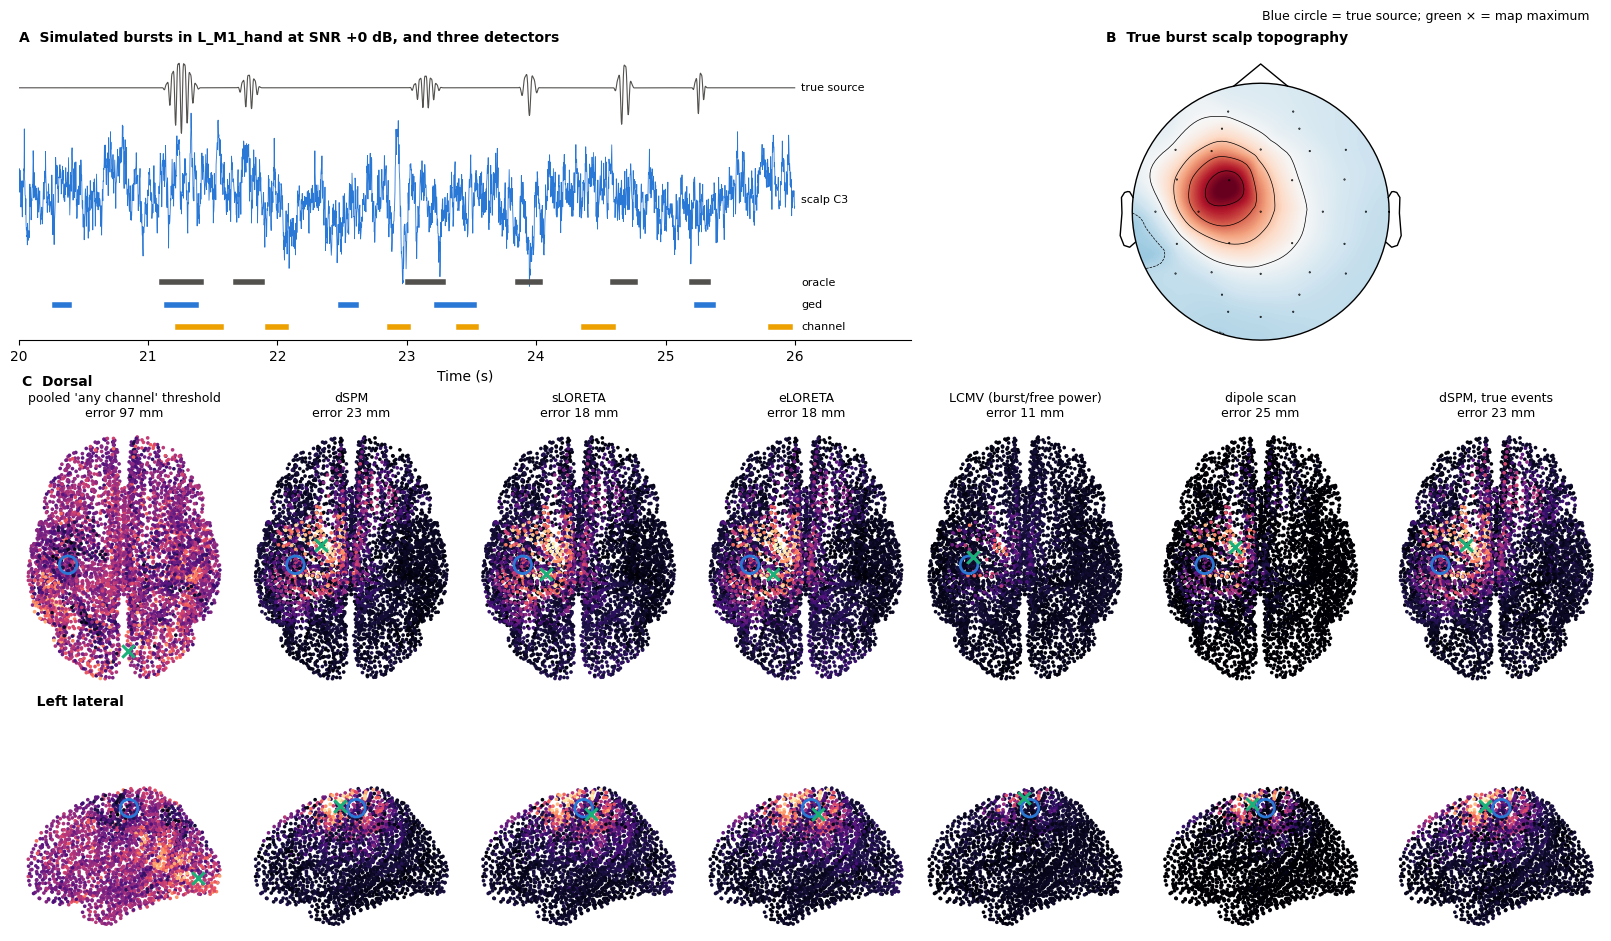

In [11]:
fig = fig_example(anat, CFG)
fig.savefig(OUT_DIR / "fig1_example.png", dpi=200)
plt.show()

In [12]:
print("Pipeline × location × SNR sweep …")
df = run_sweep(anat, CFG)
df.to_csv(OUT_DIR / "sweep_results.csv", index=False)
print("\nLocalization summary (all regions pooled):")
print(summary_table(df).to_string())
det_summary = df[df.kind == "detection"].groupby(["method", "snr_db"])[["precision", "recall", "f1",
                                                                        "n_detected"]].median().round(3)
print("\nDetection summary:")
print(det_summary.to_string())
flagged = df[(df.kind == "localization") & (df.method == "pooled_any_dSPM")]
print("\nRegion accuracy (dSPM, GED events / true events) at the highest SNR:")
hi = df[(df.kind == "localization") & (df.snr_db == max(CFG["snr_db"])) & df.method.isin(["dSPM", "dSPM_oracle"])]
print(hi.pivot_table(index="region", columns="method", values=["peak_err_mm", "region_correct"],
                     aggfunc={"peak_err_mm": "median", "region_correct": "mean"}).round(2).to_string())
print(f"\nPooled 'any channel' rule: {100 * flagged.fraction_flagged.mean():.1f} % of samples flagged; "
      f"peak latency within 50 ms of the ±0.5 s epoch edge in "
      f"{np.mean(np.abs(flagged.peak_time_s) >= 0.45) * 100:.0f} % of recordings")

Pipeline × location × SNR sweep …
  sweep 560/560  (1366 s, ~   0 s left)

Localization summary (all regions pooled):
                        peak_err_mm  dispersion_mm    auc  region_acc  hemi_acc
method          snr_db                                                         
LCMV            -10.0        71.245         73.474  0.558       0.150     0.543
                -5.0         27.310         56.983  0.799       0.333     0.771
                 0.0         14.918         31.160  0.965       0.667     0.979
                 5.0         10.925         27.611  0.962       0.842     1.000
dSPM            -10.0        65.987         74.730  0.561       0.125     0.521
                -5.0         35.340         65.093  0.821       0.333     0.771
                 0.0         20.740         48.030  0.980       0.667     0.936
                 5.0         14.918         43.390  0.983       0.733     0.993
dSPM_oracle     -10.0        14.918         62.900  0.979       0.775     0.957
  

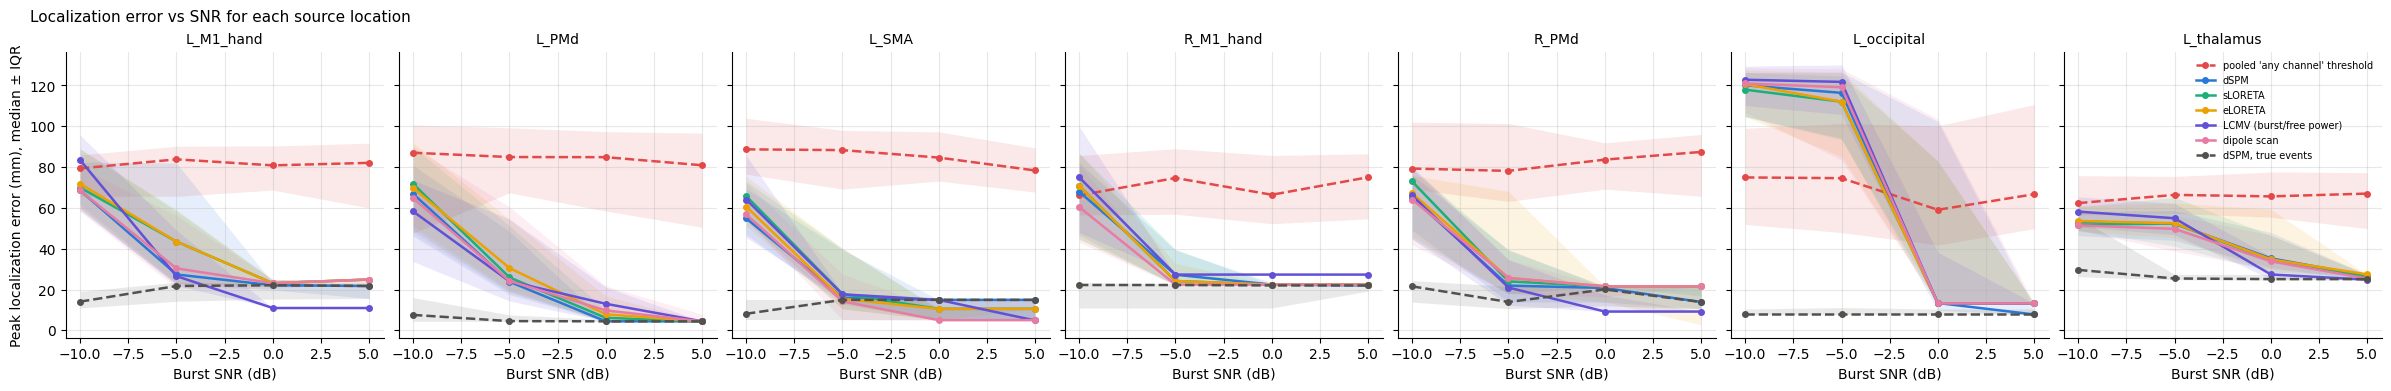

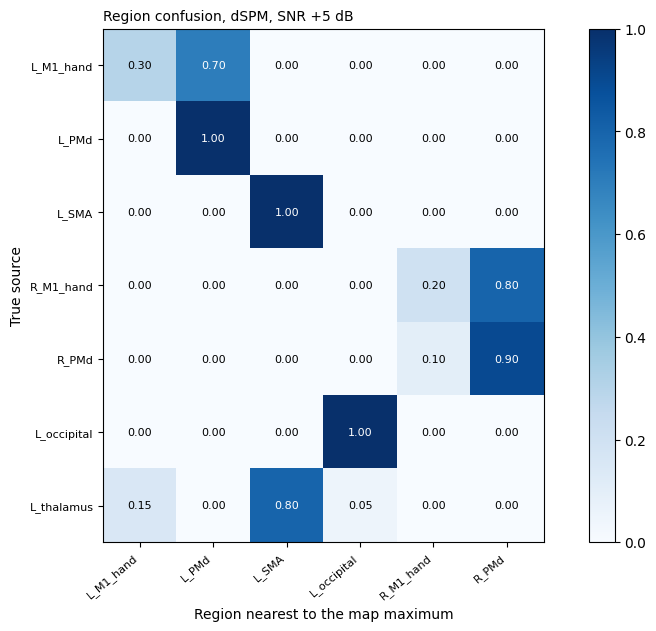

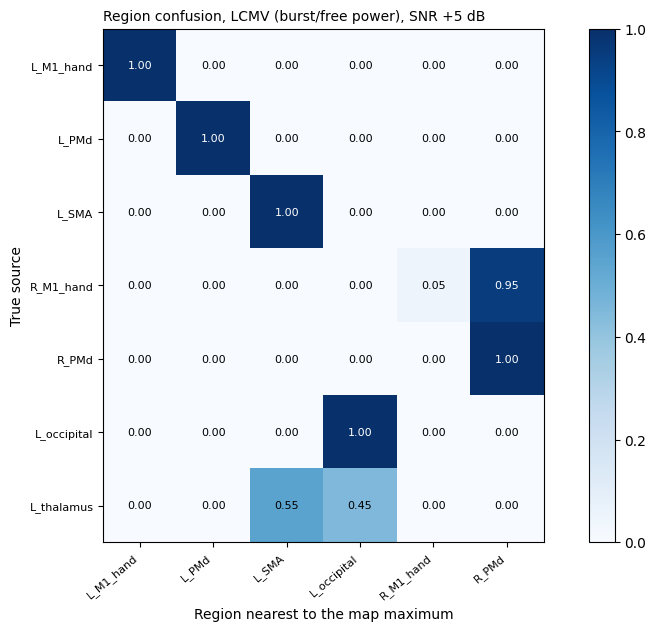

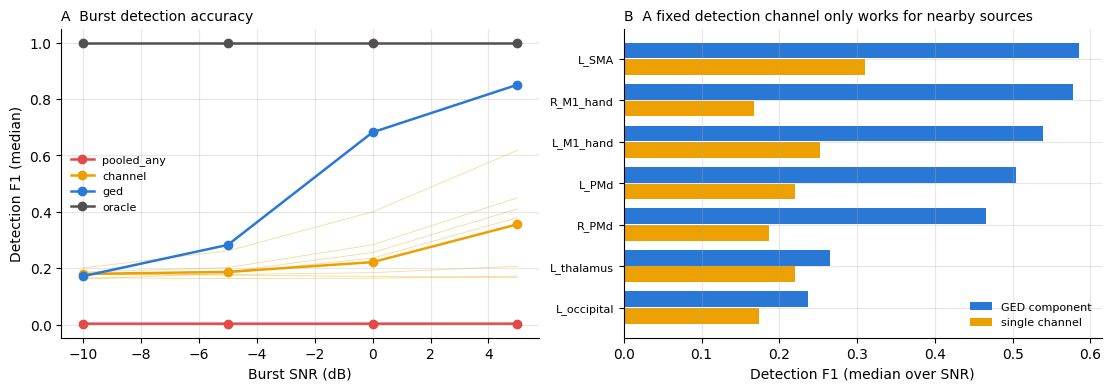

In [13]:
for f, name in ((fig_error_vs_snr(df, CFG), "fig2_error_vs_snr.png"),
                (fig_confusion(df, "dSPM", snr_db=max(CFG["snr_db"])), "fig3_confusion_dSPM.png"),
                (fig_confusion(df, "LCMV", snr_db=max(CFG["snr_db"])), "fig3b_confusion_LCMV.png"),
                (fig_detection(df), "fig4_detection.png")):
    f.savefig(OUT_DIR / name, dpi=200)
plt.show()

Matched-head-model control …
anatomy (fsaverage, MATCHED control): generating sources 20484, inverse sources 5124, 22 s
   L_M1_hand    cortical  centroid [-38.7 -22.8  58.4] patch vertices 78
   L_PMd        cortical  centroid [-20.2  -9.4  61.7] patch vertices 67
   L_SMA        cortical  centroid [-6.7 -6.3 59.3] patch vertices 60
   R_M1_hand    cortical  centroid [ 38.7 -21.1  58.4] patch vertices 64
   R_PMd        cortical  centroid [ 22.7 -11.4  61.8] patch vertices 71
   L_occipital  cortical  centroid [-26.  -93.3   3.6] patch vertices 47
   L_thalamus   deep      centroid [-12. -18.   8.] patch vertices 0
   centroid distance L_M1_hand–L_PMd: 23.1 mm
   centroid distance R_M1_hand–R_PMd: 19.0 mm
   centroid distance L_PMd–L_SMA: 14.1 mm
  control 280/280  ( 761 s, ~   0 s left)
method         LCMV               dSPM            dSPM_oracle           
head_model  matched mismatched matched mismatched     matched mismatched
region                                                

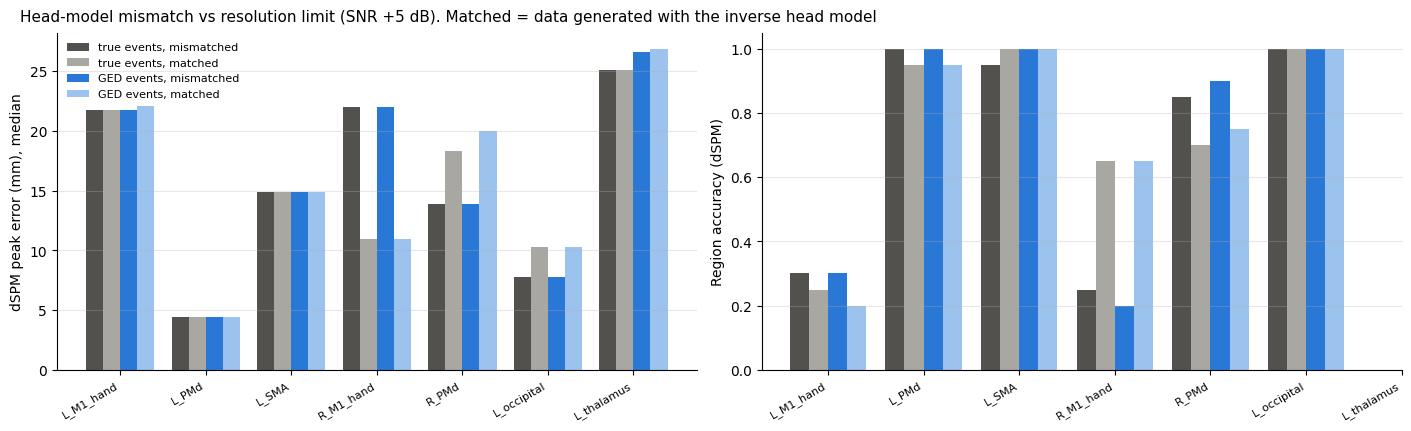

In [14]:
if __name__ == "__main__" and CFG["run_matched_control"]:
    print("Matched-head-model control …")
    anat_matched = build_anatomy(CFG, matched=True, reuse_inverse=anat)
    df_ctrl = run_sweep(anat_matched, {**CFG, "snr_db": CFG["control_snr_db"]}, label="control")
    df_ctrl.to_csv(OUT_DIR / "matched_control_results.csv", index=False)
    both = pd.concat([df[df.snr_db.isin(CFG["control_snr_db"])], df_ctrl])
    both = both[both.kind == "localization"]
    print(both[both.method.isin(["dSPM", "dSPM_oracle", "LCMV"])].pivot_table(
        index="region", columns=["method", "head_model"], values="peak_err_mm", aggfunc="median").round(1).to_string())
    fig_control(df, df_ctrl).savefig(OUT_DIR / "fig7_matched_control.png", dpi=200)
    plt.show()

Noise-only recordings …


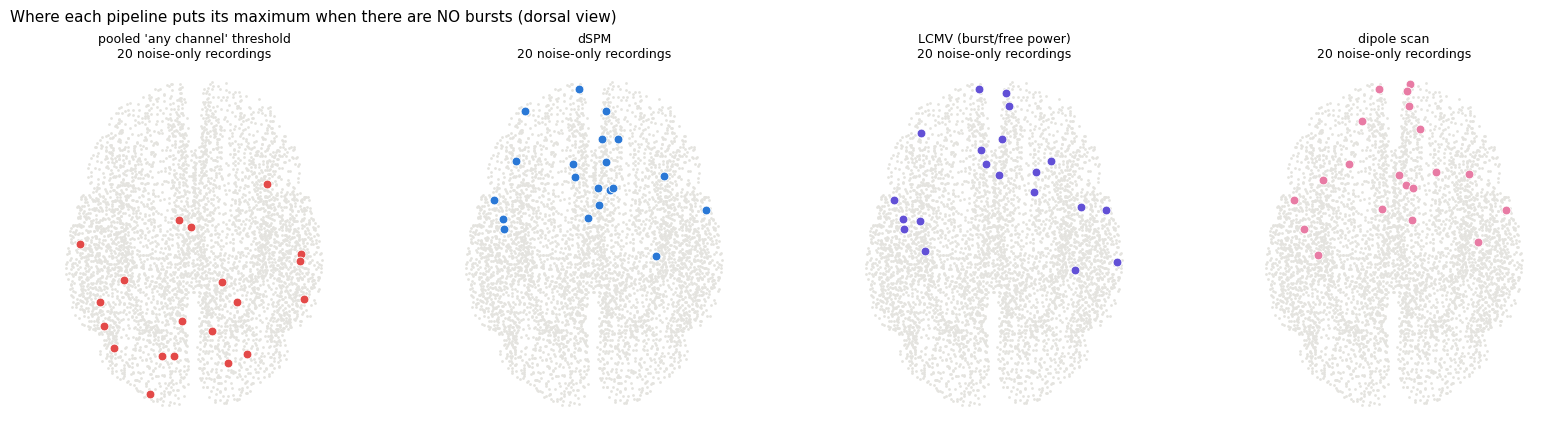

In [15]:
print("Noise-only recordings …")
dfn = run_noise_only(anat, CFG)
dfn.to_csv(OUT_DIR / "noise_only_results.csv", index=False)
fig_noise_only(dfn, anat).savefig(OUT_DIR / "fig5_noise_only.png", dpi=200)
plt.show()

OFF/ON group simulation (same true source in both conditions) …
  group: patient 15/15
    threshold                    metric      OFF       ON   OFF-ON  wilcoxon_p
per_recording          ged:true_rate_hz   0.7617   0.6567   0.1050      0.0006
per_recording               ged:rate_hz   0.8961   0.9150  -0.0189      0.1975
per_recording                ged:dur_ms 174.3424 167.4428   6.8996      0.0730
per_recording                 dSPM:nave 107.0000 109.5333  -2.5333      0.1311
per_recording          dSPM:peak_err_mm  32.6936  53.5514 -20.8578      0.0229
per_recording        dSPM:dispersion_mm  66.4415  76.7808 -10.3392      0.0006
per_recording   dSPM_oracle:peak_err_mm  17.1046  15.1213   1.9833      0.0747
per_recording dSPM_oracle:dispersion_mm  54.3409  58.0509  -3.7100      0.0020
       shared          ged:true_rate_hz   0.7617   0.6567   0.1050      0.0006
       shared               ged:rate_hz   0.9161   0.8922   0.0239      0.1551
       shared                ged:dur_ms 172.

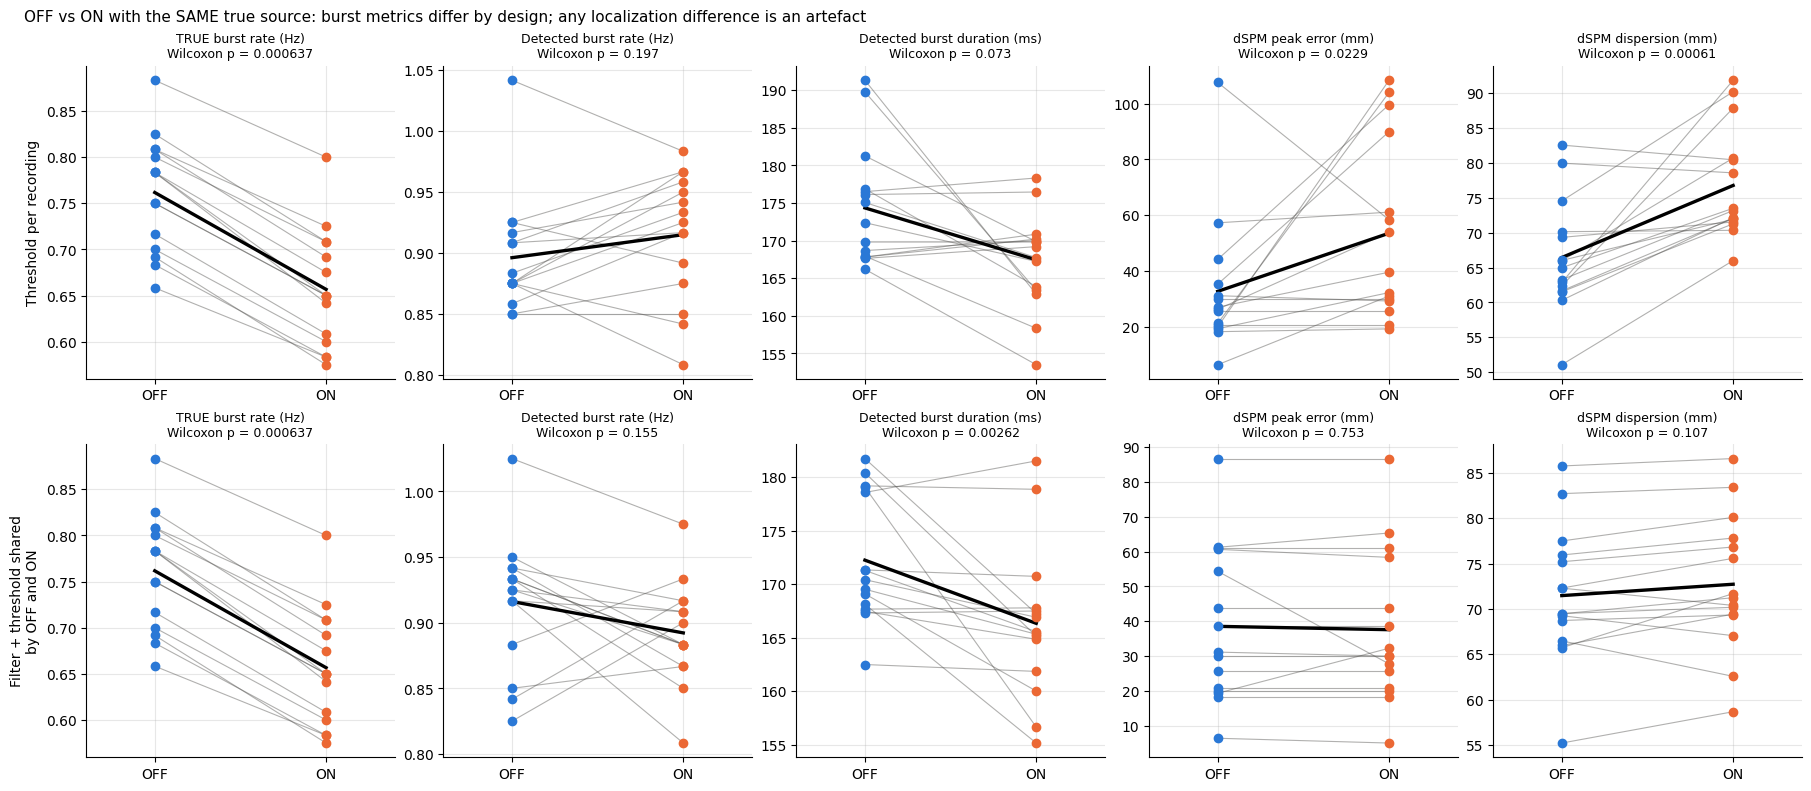

Done in 2345 s. Results in burst_sim_results/


In [16]:
print("OFF/ON group simulation (same true source in both conditions) …")
dfg = run_group(anat, CFG)
dfg.to_csv(OUT_DIR / "group_offon_results.csv", index=False)
print(group_table(dfg).to_string(index=False))
fig_group(dfg).savefig(OUT_DIR / "fig6_group_offon.png", dpi=200)
plt.show()
print(f"Done in {time.time() - t_start:.0f} s. Results in {OUT_DIR.name}/")